In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load the dataset
df = pd.read_csv('IRIS_Dataset.csv')  

In [3]:
# Provide the first 5 rows of the dataset to get an overview of the data.
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
# Gives the basic information about the dataset, including the number of non-null entries, data types, and memory usage.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [5]:
# Describe the dataset as statistical summary of the numerical columns.
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
# Check the shape of the dataset to understand the number of rows and columns.
df.shape

(150, 5)

In [7]:
# Check the column names of the dataset to understand the features available for analysis.
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

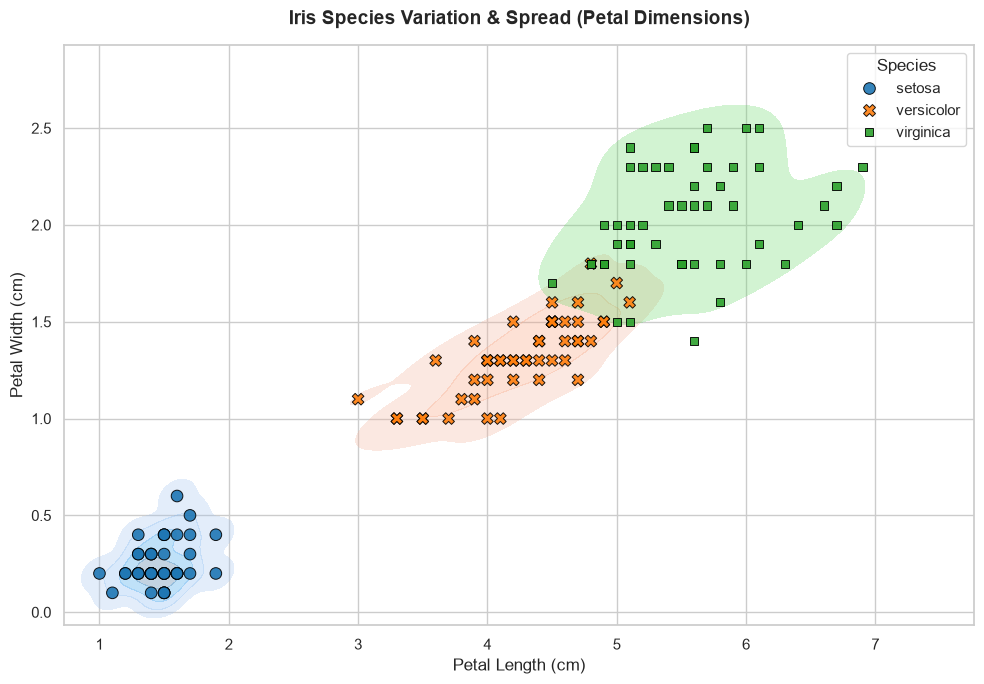


--- Standard Deviation (Spread) Summary ---
            petal_length_std  petal_width_std  sepal_length_std  \
species                                                           
setosa                 0.174            0.107             0.352   
versicolor             0.470            0.198             0.516   
virginica              0.552            0.275             0.636   

            sepal_width_std  
species                      
setosa                0.381  
versicolor            0.314  
virginica             0.322  


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# CSVs has names 'Iris-setosa' ,clean and transform names to sirf 'setosa' only:
df["species"] = df["species"].str.replace("Iris-", "")

# SPREAD AUR DENSITY SCATTER PLOT

plt.figure(figsize=(10, 7))
sns.set_theme(style="whitegrid")

custom_palette = {
    "setosa": "#1f77b4",
    "versicolor": "#ff7f0e",
    "virginica": "#2ca02c",
}

# 1. Shaded Density Contours (Spread area)
sns.kdeplot(
    data=df,
    x="petal_length",  
     y="petal_width",
    hue="species",
    palette=custom_palette,
    levels=5,
    fill=True,
    alpha=0.3,
    warn_singular=False,
    legend=False,
)

# 2. Dotted Points (Actual Samples)
sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    palette=custom_palette,
    style="species",
    s=70,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.9,
)

plt.title(
    "Iris Species Variation & Spread (Petal Dimensions)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Petal Length (cm)", fontsize=12)
plt.ylabel("Petal Width (cm)", fontsize=12)
plt.legend(title="Species", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


# SPREAD (VARIANCE) SUMMARY TABLE
# Groupby karke direct numerical columns ka spread (std) nikalna
spread_summary = (
    df.groupby("species")
    .agg(
        petal_length_std=("petal_length", "std"),
        petal_width_std=("petal_width", "std"),
        sepal_length_std=("sepal_length", "std"),
        sepal_width_std=("sepal_width", "std"),
    )
    .round(3)
)

print("\n--- Standard Deviation (Spread) Summary ---")
print(spread_summary)